In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import csv
import random

In [ ]:
counter = 0
base_filename1 = './up_label/IMU_up_test'
base_filename2 = './down_label/IMU_down_test'
base_filename3 = './stationary_label/IMU_stationary_test'
fileFormat = '.csv'

# 0 : Up, 1 : Down, 2: Stationary


train_x = []
train_y = []

test_x = []
test_y = []

# Training Data
for i in range(80):
    counter += 1
    fileName1 = f"{base_filename1}_{counter}{fileFormat}"
    fileName2 = f"{base_filename2}_{counter}{fileFormat}"
    fileName3 = f"{base_filename3}_{counter}{fileFormat}"

    train_data1 = np.genfromtxt(fileName1, delimiter=',', skip_header=1)
    train_data2 = np.genfromtxt(fileName2, delimiter=',', skip_header=1)
    train_data3 = np.genfromtxt(fileName3, delimiter=',', skip_header=1)

    train_x.append(train_data1[:,1])
    train_x.append(train_data2[:,1])
    train_x.append(train_data3[:,1])

    train_y.append(0)
    train_y.append(1)
    train_y.append(2)

# Test Data
for i in range(20):
    counter += 1
    fileName1 = f"{base_filename1}_{counter}{fileFormat}"
    fileName2 = f"{base_filename2}_{counter}{fileFormat}"
    fileName3 = f"{base_filename3}_{counter}{fileFormat}"

    test_data1 = np.genfromtxt(fileName1, delimiter=',', skip_header=1)
    test_data2 = np.genfromtxt(fileName2, delimiter=',', skip_header=1)
    test_data3 = np.genfromtxt(fileName3, delimiter=',', skip_header=1)

    test_x.append(test_data1[:,1])
    test_x.append(test_data2[:,1])
    test_x.append(test_data3[:,1])

    test_y.append(0)
    test_y.append(1)
    test_y.append(2)


train_x = np.array(train_x)
train_y = np.array(train_y)
test_x = np.array(test_x)
test_y = np.array(test_y)

print(train_x.shape)
print(train_y.shape)
print(test_x.shape)
print(test_y.shape)

(240, 1000)
(240,)
(60, 1000)
(60,)


In [ ]:
mnist = tf.keras.datasets.mnist

(train_x, train_y), (test_x, test_y) = mnist.load_data()

train_x, test_x = train_x/255.0, test_x/255.0

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
train_x = train_x.reshape((train_x.shape[0], 1000, 1))
test_x = test_x.reshape((test_x.shape[0], 1000, 1))

In [ ]:
print(train_x.shape)
print(test_x.shape)

(240, 1000, 1)
(60, 1000, 1)


In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Conv1D(filters = 32,
                           kernel_size = 3,
                           activation = 'relu',
                           padding = 'SAME',
                           input_shape = (1000,1)),

    tf.keras.layers.MaxPool1D(2),

    tf.keras.layers.Conv1D(filters = 64,
                           kernel_size = 3,
                           activation = 'relu',
                           padding = 'SAME',
                           input_shape = (500,1)),

    tf.keras.layers.MaxPool1D(2),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(units = 128, activation = 'relu'),

    tf.keras.layers.Dense(units = 3, activation = 'softmax')    # 3개 클래스로 분류
])

# 모델 컴파일
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# 모델 요약
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)                    │ (None, 1000, 32)            │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_2 (MaxPooling1D)       │ (None, 500, 32)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_3 (Conv1D)                    │ (None, 500, 64)             │           6,208 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_3 (MaxPooling1D)       │ (None, 250, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 16000)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │       2,048,128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,054,851 (7.84 MB)

 Trainable params: 2,054,851 (7.84 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.fit(train_x, train_y, batch_size = 50, epochs = 5)

Epoch 1/5
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 162ms/step - accuracy: 0.9856 - loss: 0.0388
Epoch 2/5
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 158ms/step - accuracy: 0.9936 - loss: 0.0446
Epoch 3/5
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 111ms/step - accuracy: 0.9722 - loss: 0.1044
Epoch 4/5
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step - accuracy: 0.9847 - loss: 0.0497
Epoch 5/5
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step - accuracy: 0.9906 - loss: 0.0375


In [ ]:
test_loss, test_acc = model.evaluate(test_x, test_y)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 1.0000 - loss: 0.0197 


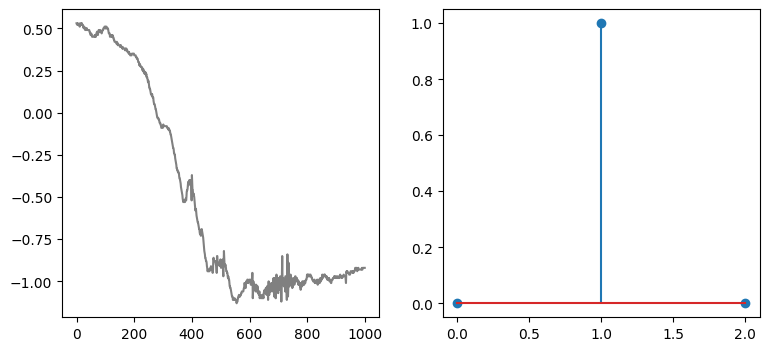

Prediction : 1
Predicted movement : Down


In [ ]:
indexNum = random.randint(0, 59)
test_accX = test_x[[indexNum]]


pred = model.predict(test_accX, verbose = 0)
myPred = np.argmax(pred, axis = 1)



test_accX = test_accX.reshape((test_accX.shape[1]))
timeData = list(range(len(test_accX)))

plt.figure(figsize = (9,4))

plt.subplot(1,2,1)
plt.plot(timeData, test_accX, 'gray')
plt.subplot(1,2,2)
plt.stem(pred[0])
plt.show()

print('Prediction : {}'.format(myPred[0]))
if (myPred[0] == 0):
    print("Predicted movement : Up")
elif (myPred[0] == 1):
    print("Predicted movement : Down")
elif (myPred[0] == 2):
    print("Predicted movement : Stationary")